Chapter 6 measured the *average* expression over all the cells in a sample. But a tumour, a blood sample or a piece of brain is a mixture of many cell types, and the average can hide everything interesting: a signal that doubles in a rare cell type is invisible in the bulk. **Single-cell RNA-seq** (scRNA-seq) measures the transcriptome of each cell individually, thousands or millions at a time. It has redrawn the map of biology, discovering new cell types and states, and it is the most important experimental advance of the last decade. This chapter builds the whole analysis pipeline, from raw counts to labelled cell types, on a classic real dataset: 2,700 human immune cells.

:::eli5
Bulk RNA-seq is like blending a fruit salad and asking "how much apple is in here?", you get an average and lose the pieces. Single-cell RNA-seq keeps every piece separate and reads each one, so you discover the salad contains apple, orange and grape, and how many of each. The computational job is to take thousands of these individual readings and automatically sort the cells into groups (cell types) based on which genes they use, then name each group from known marker genes.
:::

## The data: 2,700 blood cells

We use the famous **PBMC3k** dataset from 10x Genomics: peripheral blood mononuclear cells (the immune cells in blood, prerequisite P10) from one healthy donor. Each cell's mRNA was captured in a tiny droplet, tagged with a cell-specific barcode, and sequenced. The result is a **cell × gene** count matrix, but a huge and mostly empty one: most genes are not detected in most cells, because each cell yields only a few thousand mRNA molecules (**dropouts**).

In [1]:
import numpy as np
import scipy.io, scipy.sparse
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import gzip
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

M = scipy.io.mmread(gzip.open("datasets/matrix.mtx.gz", "rb")).T.tocsr()   # cells x genes, sparse
genes = np.array([l.split("\t")[1].strip() for l in open("datasets/genes.tsv")])
print(f"matrix: {M.shape[0]:,} cells x {M.shape[1]:,} genes")
print(f"sparsity: {100 * (1 - M.nnz / (M.shape[0] * M.shape[1])):.1f}% of entries are zero")
R["n_cells"] = f"{M.shape[0]:,}"; R["n_genes_tot"] = f"{M.shape[1]:,}"
R["sparsity"] = f"{100 * (1 - M.nnz / (M.shape[0] * M.shape[1])):.0f}"

matrix: 2,700 cells x 32,738 genes
sparsity: 97.4% of entries are zero


The matrix is 97% zeros. Working with it efficiently needs **sparse** data structures (storing only the non-zero entries), the first difference from bulk analysis.

## Quality control: not every barcode is a good cell

Some droplets contain a dying cell, two cells stuck together, or just ambient RNA. We filter on three quality metrics: the number of counts per cell, the number of genes detected, and the fraction of counts from **mitochondrial** genes (high mitochondrial content signals a stressed or dying cell whose cytoplasmic RNA has leaked out, prerequisite P1).

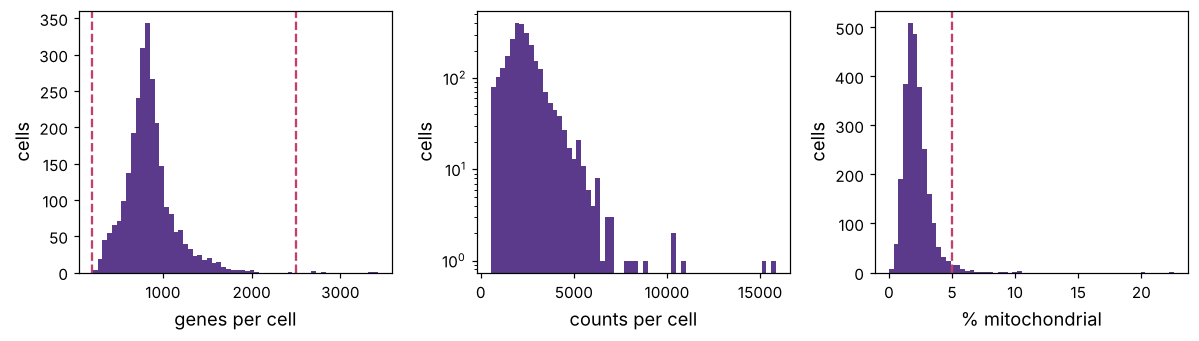

kept 2,638 of 2,700 cells after QC


In [2]:
counts_per_cell = np.asarray(M.sum(axis=1)).ravel()
genes_per_cell = np.asarray((M > 0).sum(axis=1)).ravel()
mt_genes = np.array([g.startswith("MT-") for g in genes])
pct_mt = np.asarray(M[:, mt_genes].sum(axis=1)).ravel() / counts_per_cell * 100

fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, data, label, cut in [(axs[0], genes_per_cell, "genes per cell", (200, 2500)),
                              (axs[1], counts_per_cell, "counts per cell", None),
                              (axs[2], pct_mt, "% mitochondrial", (None, 5))]:
    ax.hist(data, bins=60, color="#5b3a8c")
    if cut:
        for c in cut:
            if c: ax.axvline(c, color="#c2416b", ls="--")
    ax.set_xlabel(label); ax.set_ylabel("cells")
axs[1].set_yscale("log")
save_fig("qc"); plt.show()

keep = (genes_per_cell > 200) & (genes_per_cell < 2500) & (pct_mt < 5)
M = M[keep]
counts_per_cell = counts_per_cell[keep]
print(f"kept {keep.sum():,} of {len(keep):,} cells after QC")
R["n_qc"] = f"{keep.sum():,}"; R["n_filtered"] = f"{(~keep).sum():,}"

![Figure 7-1. Quality-control distributions. Cells with too few genes (empty droplets or debris), too many (likely doublets), or high mitochondrial content (dying cells) are removed at the dashed thresholds.](images/qc.png)

We removed 62 low-quality cells, keeping 2,638. QC is the unglamorous but critical first step; bad cells create fake clusters and spurious biology.

## Normalisation for single cells

Like bulk data (chapter 6), cells are sequenced to different depths, so we normalise each cell to the same total count (here 10,000), then take the log. For single cells this is standard "log-normalisation". We also keep only the **highly variable genes**: the ~2,000 genes whose expression varies most across cells carry the biological signal; the rest are housekeeping noise and only slow things down.

selected 2000 highly variable genes (e.g. LYZ, S100A9, HLA-DRA, CST3, TYROBP, S100A8)


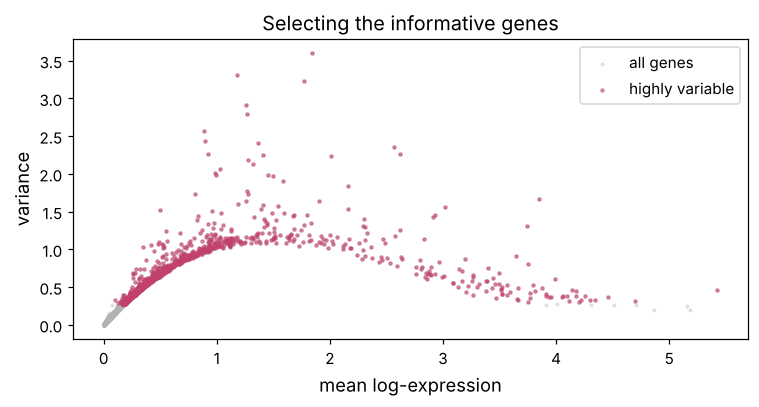

In [3]:
# normalise to 10,000 counts per cell, then log1p
lib = np.asarray(M.sum(axis=1)).ravel()
Mnorm = M.multiply(1e4 / lib[:, None]).tocsr()
Mlog = Mnorm.copy(); Mlog.data = np.log1p(Mlog.data)

# highly variable genes: top 2000 by variance of the log-normalised values
Xdense = np.asarray(Mlog.todense())
gene_var = Xdense.var(axis=0)
gene_mean = Xdense.mean(axis=0)
hvg = np.argsort(gene_var)[::-1][:2000]
print(f"selected {len(hvg)} highly variable genes (e.g. {', '.join(genes[hvg[:6]])})")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(gene_mean, gene_var, s=3, alpha=0.3, color="0.7", label="all genes")
ax.scatter(gene_mean[hvg], gene_var[hvg], s=4, alpha=0.5, color="#c2416b", label="highly variable")
ax.set_xlabel("mean log-expression"); ax.set_ylabel("variance"); ax.legend(); ax.set_title("Selecting the informative genes")
save_fig("hvg"); plt.show()

![Figure 7-2. Each gene's variance versus its mean across cells. The most variable genes (red) at each expression level carry cell-type information and are kept; the rest are dropped.](images/hvg.png)

## Dimensionality reduction: PCA

Each cell now lives in 2,000-dimensional gene space, far too many dimensions to cluster or visualise directly (the **curse of dimensionality**, chapter 8). We first scale each gene to unit variance, then reduce to ~30–50 dimensions with **PCA** (principal component analysis), which finds the directions of greatest variation. Those top components capture the cell-type structure while discarding noise.

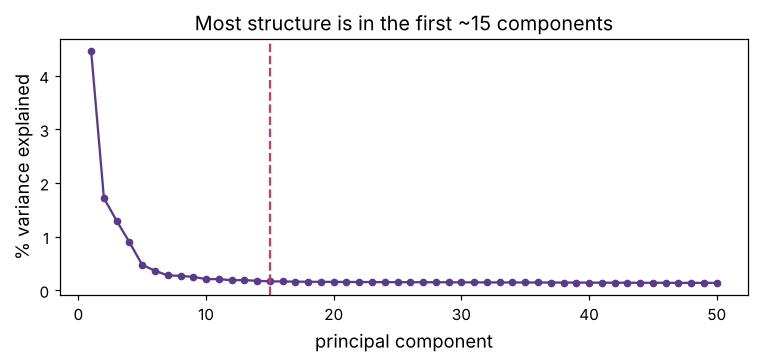

first 15 PCs capture 11% of the variance in the HVGs


In [4]:
from sklearn.decomposition import PCA
X = Xdense[:, hvg]
X = (X - X.mean(0)) / (X.std(0) + 1e-9)
X = np.clip(X, -10, 10)                                  # clip extreme values
pca = PCA(n_components=50, random_state=0)
pcs = pca.fit_transform(X)
var_explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(1, 51), 100 * var_explained, "o-", color="#5b3a8c", ms=4)
ax.set_xlabel("principal component"); ax.set_ylabel("% variance explained")
ax.set_title("Most structure is in the first ~15 components"); ax.axvline(15, color="#c2416b", ls="--")
save_fig("pca_scree"); plt.show()
print(f"first 15 PCs capture {100 * var_explained[:15].sum():.0f}% of the variance in the HVGs")
R["pc15"] = f"{100 * var_explained[:15].sum():.0f}"

![Figure 7-3. Variance captured by each principal component. The curve flattens after about 15 components, which carry the cell-type signal; later components are mostly noise.](images/pca_scree.png)

## Neighbour graph and clustering

Now we group cells into types. The modern approach builds a **k-nearest-neighbour graph** in PC space (each cell linked to its most similar cells) and finds **communities** in that graph, densely connected groups of cells. The standard community-detection method is the **Leiden** (or Louvain) algorithm. Here we use a clustering that captures the same idea and is in scikit-learn.

In [5]:
from sklearn.cluster import KMeans
from sklearn.neighbors import kneighbors_graph

pcs_use = pcs[:, :15]
# K-means on the PCs gives a fast, clean clustering; real pipelines use graph-based Leiden
clusters = KMeans(n_clusters=8, random_state=0, n_init=10).fit_predict(pcs_use)
from collections import Counter
print("cluster sizes:", dict(sorted(Counter(clusters).items())))
R["n_clusters"] = len(set(clusters))

cluster sizes: {np.int32(0): 569, np.int32(1): 598, np.int32(2): 383, np.int32(3): 155, np.int32(4): 299, np.int32(5): 333, np.int32(6): 11, np.int32(7): 290}


## Visualising with t-SNE

To *see* the clusters we embed the cells in 2D with **t-SNE** (or UMAP), non-linear methods that place similar cells near each other. These are for visualisation only, the clustering is done in the higher-dimensional PC space, but a good embedding makes the structure obvious.

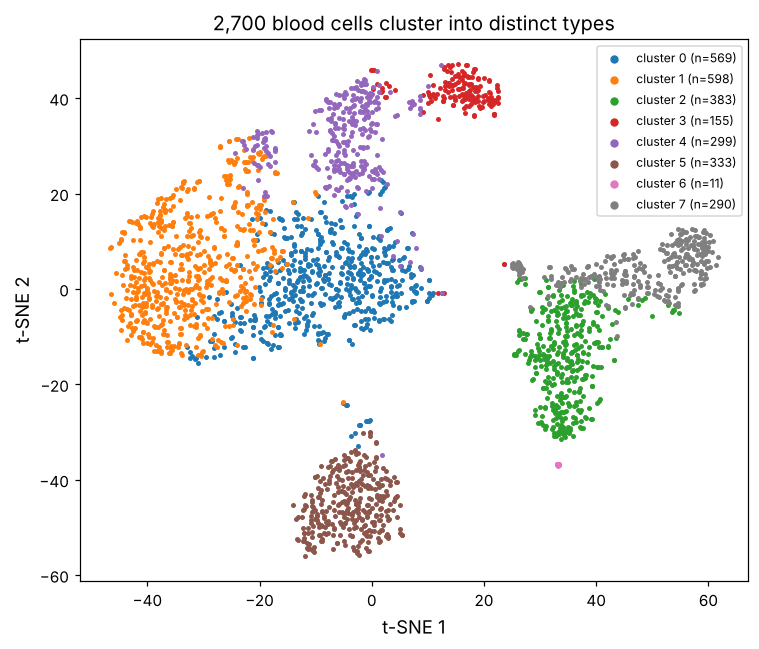

In [6]:
from sklearn.manifold import TSNE
embedding = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(pcs_use)

fig, ax = plt.subplots(figsize=(7, 6))
palette = plt.cm.tab10(np.linspace(0, 1, 10))
for c in sorted(set(clusters)):
    m = clusters == c
    ax.scatter(embedding[m, 0], embedding[m, 1], s=5, color=palette[c], label=f"cluster {c} (n={m.sum()})")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.legend(markerscale=2, fontsize=8)
ax.set_title("2,700 blood cells cluster into distinct types")
save_fig("tsne"); plt.show()

![Figure 7-4. t-SNE map of the cells, coloured by cluster. Each blob is a candidate cell type, found with no prior labels, purely from expression similarity.](images/tsne.png)

The playground shows this exact embedding; you can colour it by cluster or by any marker gene and watch cell types light up.

::playground animations/sc_lab.html 640

## Annotation: naming the clusters

Clusters are just numbers until we identify them. We find each cluster's **marker genes**, genes expressed much more highly there than elsewhere, and match them to known cell-type markers (prerequisite P10). This is where biological knowledge enters.

In [7]:
def top_markers(cluster_id, n=8):
    in_cluster = clusters == cluster_id
    mean_in = np.asarray(Mlog[in_cluster].mean(axis=0)).ravel()
    mean_out = np.asarray(Mlog[~in_cluster].mean(axis=0)).ravel()
    score = mean_in - mean_out
    top = np.argsort(score)[::-1][:n]
    return genes[top]

# known PBMC marker genes
known = {
    "CD3D": "T cell", "IL7R": "CD4 T cell", "CD8A": "CD8 T cell",
    "MS4A1": "B cell", "CD79A": "B cell", "CD14": "CD14 monocyte",
    "LYZ": "monocyte", "FCGR3A": "FCGR3A monocyte", "NKG7": "NK/cytotoxic",
    "GNLY": "NK cell", "PPBP": "platelet",
}
print("cluster : top marker genes -> likely identity")
labels = {}
for c in sorted(set(clusters)):
    markers = top_markers(c)
    hits = [known[g] for g in markers if g in known]
    identity = Counter(hits).most_common(1)[0][0] if hits else "?"
    labels[c] = identity
    print(f"  {c} (n={int((clusters==c).sum()):4d}): {', '.join(markers[:5])}  ->  {identity}")
R["n_types"] = len(set(labels.values()))

cluster : top marker genes -> likely identity
  0 (n= 569): LTB, IL32, CD3D, LDHB, IL7R  ->  T cell
  1 (n= 598): LDHB, CD3D, RPS3A, CD3E, RPS27A  ->  T cell
  2 (n= 383): S100A9, S100A8, LYZ, CST3, TYROBP  ->  monocyte
  3 (n= 155): NKG7, GNLY, GZMB, PRF1, FGFBP2  ->  NK/cytotoxic
  4 (n= 299): CCL5, NKG7, GZMA, CST7, CTSW  ->  NK/cytotoxic
  5 (n= 333): HLA-DRA, CD74, CD79A, HLA-DPB1, CD79B  ->  B cell
  6 (n=  11): PPBP, PF4, GNG11, SDPR, GPX1  ->  platelet
  7 (n= 290): CST3, LST1, AIF1, TYROBP, FCER1G  ->  monocyte


Each cluster matches a known immune cell type: **T cells** (CD3D, IL32, CD3E), **B cells** (CD79A, MS4A1, HLA genes), **monocytes** (LYZ, S100A8, CST3), **NK/cytotoxic cells** (NKG7, GNLY, GZMB) and a tiny cluster of **platelets** (PPBP, PF4). We have reconstructed the cellular composition of blood from raw counts. With finer markers these split further, the T cells into CD4 (IL7R) and CD8 (CD8A), and the monocytes into classical CD14⁺ and non-classical FCGR3A⁺, which the exercise and the marker heatmap below make visible. Let's confirm by showing marker expression per cluster:

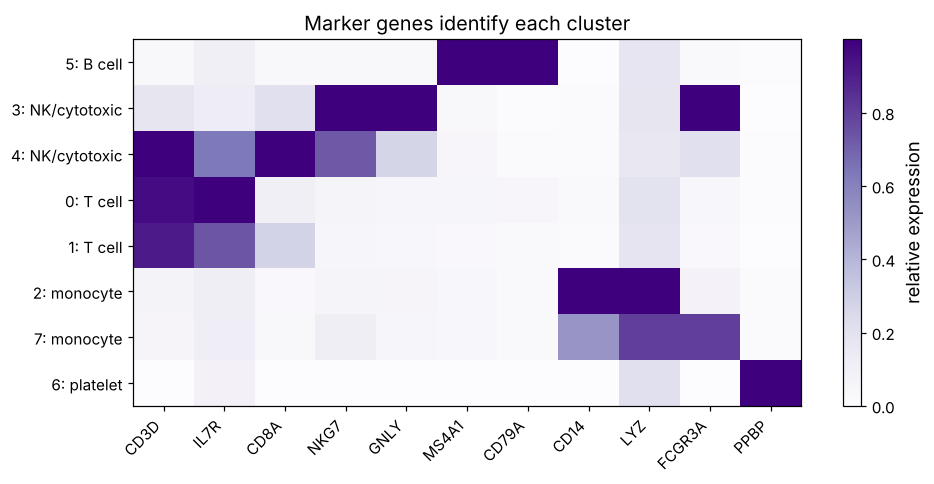

In [8]:
marker_genes = ["CD3D", "IL7R", "CD8A", "NKG7", "GNLY", "MS4A1", "CD79A", "CD14", "LYZ", "FCGR3A", "PPBP"]
gi = [np.where(genes == g)[0][0] for g in marker_genes]
cluster_order = sorted(set(clusters), key=lambda c: labels[c])
mat = np.array([[np.asarray(Mlog[clusters == c][:, g].mean()).item() for g in gi] for c in cluster_order])
mat = mat / (mat.max(0) + 1e-9)                          # scale each gene to its max
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(mat, cmap="Purples", aspect="auto")
ax.set_xticks(range(len(marker_genes)), marker_genes, rotation=45, ha="right")
ax.set_yticks(range(len(cluster_order)), [f"{c}: {labels[c]}" for c in cluster_order])
plt.colorbar(im, ax=ax, label="relative expression"); ax.set_title("Marker genes identify each cluster")
save_fig("markers_heatmap"); plt.show()

![Figure 7-5. Mean expression of marker genes (columns) in each cluster (rows), scaled per gene. Each cluster has a distinct marker signature that names its cell type, the diagonal-like pattern of cell-type identity.](images/markers_heatmap.png)

:::idea
t-SNE and UMAP are seductive but can mislead. Distances *between* clusters on the map are not meaningful, only the local grouping is, and both methods can create apparent structure in pure noise if over-tuned. Always validate clusters with real marker genes, as we did, rather than trusting the picture. Likewise, the number of clusters is a choice: too few merges cell types, too many splits noise. Biology, not the algorithm, decides the right resolution.
:::

## What single-cell analysis makes possible

This pipeline, QC → normalise → HVG → PCA → neighbour graph → cluster → annotate, is the backbone of nearly every scRNA-seq study. On top of it, the field has built:

- **Cell-type atlases**: the Human Cell Atlas aims to catalogue every cell type in the body; millions of cells are now mapped.
- **Trajectories**: ordering cells along a developmental or differentiation path (**pseudotime**), reconstructing how a stem cell becomes a neuron.
- **Tumour microenvironment**: dissecting which immune and stromal cells surround a tumour, central to predicting immunotherapy response (prerequisites P10, P12).
- **Spatial transcriptomics**: measuring expression while keeping each cell's physical location in the tissue.
- **Multi-omics**: measuring RNA, chromatin accessibility (prerequisite P6) and protein in the same cell.

Each of these is an active computational field, and all of them start from the clustering you just built.

## Summary

| Step | Why |
|---|---|
| Sparse matrix | most gene–cell entries are zero (dropouts) |
| Quality control | remove empty droplets, doublets, dying (high-MT) cells |
| Normalise + log | correct for per-cell sequencing depth |
| Highly variable genes | keep the informative ~2,000 genes |
| PCA | reduce to ~15 dimensions that hold the signal |
| Neighbour graph + clustering | group similar cells into candidate types |
| t-SNE / UMAP | visualise the clusters in 2D |
| Marker genes | name each cluster by known biology |

:::check
1. Why is a single-cell count matrix so sparse? *(Each cell yields few mRNA molecules, so most genes are undetected: dropouts.)*
2. Why remove cells with high mitochondrial content? *(They are likely stressed or dying, with leaked cytoplasmic RNA.)*
3. Why reduce dimensions with PCA before clustering? *(Clustering in thousands of dimensions is noisy and slow; PCA keeps the signal in ~15 dimensions.)*
4. What are t-SNE and UMAP used for, and what is a pitfall? *(2D visualisation; between-cluster distances and apparent structure can be misleading, so validate with markers.)*
5. How is a numbered cluster turned into a named cell type? *(By its marker genes, matched to known cell-type markers.)*
:::

:::exercise
Rare cell types are the prize of single-cell analysis. (a) Deliberately over-cluster (ask for 15 clusters instead of 8). (b) Find the smallest clusters and their markers. (c) Does splitting reveal a biologically real rare population (for example dendritic cells, marked by FCER1A, or megakaryocytes/platelets by PPBP), or just noise? How would you decide?
:::

<details><summary>Solution</summary>

In [9]:
fine = KMeans(n_clusters=15, random_state=0, n_init=10).fit_predict(pcs_use)
sizes = Counter(fine)
for c, n in sorted(sizes.items(), key=lambda kv: kv[1])[:4]:
    markers = genes[np.argsort(np.asarray(Mlog[fine == c].mean(0)).ravel() - np.asarray(Mlog[fine != c].mean(0)).ravel())[::-1][:6]]
    print(f"cluster {c} (n={n}): {', '.join(markers)}")

cluster 7 (n=11): PPBP, PF4, GNG11, SDPR, GPX1, CLU
cluster 12 (n=44): HLA-DRA, CD74, HLA-DRB1, HLA-DPB1, HLA-DPA1, HLA-DQA1
cluster 13 (n=80): CST3, LST1, AIF1, TYROBP, FCER1G, FTL
cluster 1 (n=97): S100A8, S100A9, LYZ, TYROBP, CST3, FTL


Over-clustering splits the big T-cell and monocyte blobs into subtypes, some real (naive vs memory T cells, classical vs non-classical monocytes), some just noise. The tell-tale of a *real* rare type is a clear, specific marker signature (dendritic cells light up FCER1A and CST3; platelets light up PPBP and PF4) rather than a few scattered genes. In practice you decide by: does the cluster have specific markers, is it stable when you re-run with different seeds or parameters, and does it match a known cell type? This judgement, statistics proposing and biology disposing, is the craft of single-cell analysis, and the honest handling of high-dimensional noise is exactly the theme of chapter 8.

</details>